In [2]:
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.metrics import brier_score_loss
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

df= pd.read_csv('/content/quebec_wildfire_data.csv')

In [3]:
df.columns

Index(['DATE_DEBUT', 'LATITUDE', 'LONGITUDE', 'MONTH', 'FIRE_RISK', 'MAX_TEMP',
       'PRECIPITATION', 'WIND_SPEED', 'MIN_HUMIDITY', '14_DAY_RAIN',
       '14_DAY_AVG_TEMP', 'DAYS_SINCE_RAIN'],
      dtype='object')

In [4]:
df.head()

,DATE_DEBUT,LATITUDE,LONGITUDE,MONTH,FIRE_RISK,MAX_TEMP,PRECIPITATION,WIND_SPEED,MIN_HUMIDITY,14_DAY_RAIN,14_DAY_AVG_TEMP,DAYS_SINCE_RAIN
0,2020-09-27,50.149426,-65.998559,9.0,0,10.7,14.8,13.8,97.0,40.5,12.450000,1.0
1,2021-05-13,46.320078,-78.928867,5.0,0,18.4,0.1,14.5,33.0,44.4,11.514286,2.0
2,2023-08-04,56.241305,-60.306565,8.0,0,7.7,0.0,18.2,95.0,48.9,9.650000,2.0
3,2023-06-01,49.519200,-72.615900,6.0,1,29.5,0.8,16.9,35.0,36.8,17.450000,8.0
4,2023-09-09,56.913125,-78.604401,9.0,0,9.5,0.0,25.7,81.0,35.8,9.835714,6.0


In [5]:
print(df.shape)
print(df.info())



(9171, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9171 entries, 0 to 9170
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   DATE_DEBUT       9171 non-null   object 
 1   LATITUDE         9171 non-null   float64
 2   LONGITUDE        9171 non-null   float64
 3   MONTH            9171 non-null   float64
 4   FIRE_RISK        9171 non-null   int64  
 5   MAX_TEMP         9171 non-null   float64
 6   PRECIPITATION    9171 non-null   float64
 7   WIND_SPEED       9171 non-null   float64
 8   MIN_HUMIDITY     9171 non-null   float64
 9   14_DAY_RAIN      9171 non-null   float64
 10  14_DAY_AVG_TEMP  9171 non-null   float64
 11  DAYS_SINCE_RAIN  9171 non-null   float64
dtypes: float64(10), int64(1), object(1)
memory usage: 859.9+ KB
None


In [6]:
print("\nMissing values:")
print(df.isnull().sum())




Missing values:
DATE_DEBUT         0
LATITUDE           0
LONGITUDE          0
MONTH              0
FIRE_RISK          0
MAX_TEMP           0
PRECIPITATION      0
WIND_SPEED         0
MIN_HUMIDITY       0
14_DAY_RAIN        0
14_DAY_AVG_TEMP    0
DAYS_SINCE_RAIN    0
dtype: int64


In [7]:
print("\nTarget distribution:")
print(df["FIRE_RISK"].value_counts())

print("\nTarget percentages:")
print(df["FIRE_RISK"].value_counts(normalize=True) * 100)



Target distribution:
FIRE_RISK
1    4618
0    4553
Name: count, dtype: int64

Target percentages:
FIRE_RISK
1    50.354378
0    49.645622
Name: proportion, dtype: float64


In [8]:
print(df.describe())

          LATITUDE    LONGITUDE        MONTH    FIRE_RISK     MAX_TEMP  \
count  9171.000000  9171.000000  9171.000000  9171.000000  9171.000000   
mean     50.050260   -70.734255     6.628176     0.503544    18.993588   
std       3.687695     5.757700     1.333246     0.500015     7.629279   
min      45.015400   -79.502041     5.000000     0.000000    -9.500000   
25%      46.882285   -75.177613     5.000000     0.000000    14.000000   
50%      49.127001   -72.035800     6.000000     1.000000    20.100000   
75%      52.617844   -66.830537     8.000000     1.000000    24.800000   
max      58.744700   -57.250000     9.000000     1.000000    34.600000   

       PRECIPITATION   WIND_SPEED  MIN_HUMIDITY  14_DAY_RAIN  14_DAY_AVG_TEMP  \
count    9171.000000  9171.000000   9171.000000   9171.00000      9171.000000   
mean        2.717544    20.076109     50.580962     39.30036        16.655760   
std         5.842298     8.553524     18.384238     24.35933         6.362697   
min      

In [9]:
features = [
    "LATITUDE",
    "LONGITUDE",
    "MAX_TEMP",
    "PRECIPITATION",
    "WIND_SPEED",
    "MIN_HUMIDITY"
]


X = df[features].copy()
y = df["FIRE_RISK"].copy()

print("Features:")
print(X.columns.tolist())

print("\nX shape:", X.shape)
print("y shape:", y.shape)
print(X.isnull().sum())

Features:
['LATITUDE', 'LONGITUDE', 'MAX_TEMP', 'PRECIPITATION', 'WIND_SPEED', 'MIN_HUMIDITY']

X shape: (9171, 6)
y shape: (9171,)
LATITUDE         0
LONGITUDE        0
MAX_TEMP         0
PRECIPITATION    0
WIND_SPEED       0
MIN_HUMIDITY     0
dtype: int64


In [10]:
# Splitting training and testing data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

print("Training distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training: (7336, 6)
Testing: (1835, 6)
Training distribution:
FIRE_RISK
1    50.354417
0    49.645583
Name: proportion, dtype: float64

Testing distribution:
FIRE_RISK
1    50.354223
0    49.645777
Name: proportion, dtype: float64


In [11]:
print(
    X_train[
        ["MAX_TEMP", "PRECIPITATION", "WIND_SPEED", "MIN_HUMIDITY"]
    ].describe()
)

          MAX_TEMP  PRECIPITATION   WIND_SPEED  MIN_HUMIDITY
count  7336.000000    7336.000000  7336.000000   7336.000000
mean     18.990758       2.722246    20.149646     50.674618
std       7.589112       5.776624     8.632904     18.383450
min      -9.500000       0.000000     4.400000     14.000000
25%      14.000000       0.000000    14.200000     36.000000
50%      20.000000       0.300000    18.000000     48.000000
75%      24.800000       2.800000    23.800000     64.000000
max      34.600000      65.400000    90.900000     98.000000


In [12]:
from lightgbm import LGBMClassifier
from sklearn.metrics import brier_score_loss


lgbm = LGBMClassifier(
    n_estimators=10000,
    learning_rate=0.03,
    max_depth=-1,
    num_leaves=63,
    min_child_samples=20,
    reg_alpha=0.0,
    reg_lambda=1.0,

    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42,
    n_jobs=-1
)

lgbm.fit(
    X_train,
    y_train,
    eval_set=[(X_test, y_test)]
)

lgb_pred = lgbm.predict(X_test)
lgb_prob = lgbm.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, lgb_pred))
print("Precision:", precision_score(y_test, lgb_pred))
print("Recall   :", recall_score(y_test, lgb_pred))
print("F1       :", f1_score(y_test, lgb_pred))
print("ROC-AUC  :", roc_auc_score(y_test, lgb_prob))
brier = brier_score_loss(y_test, lgb_prob)

print("Brier Loss:", brier)

[LightGBM] [Info] Number of positive: 3694, number of negative: 3642
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000738 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1338
[LightGBM] [Info] Number of data points in the train set: 7336, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.503544 -> initscore=0.014177
[LightGBM] [Info] Start training from score 0.014177
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Accuracy : 0.9613079019073569
Precision: 0.9571275455519829
Re

In [ ]:
from lightgbm import LGBMClassifier
import lightgbm as lgb
from sklearn.metrics import brier_score_loss
evals_result = {}

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)


lgbm = LGBMClassifier(
    n_estimators=10000,
    learning_rate=0.03,
    max_depth=-1,
    num_leaves=63,
    min_child_samples=20,
    reg_alpha=0.3,
    reg_lambda=0.2,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42,
    n_jobs=-1
)

lgbm.fit(
    X_tr,
    y_tr,
    eval_set=[(X_tr, y_tr), (X_val, y_val)],
    eval_names=["train", "validation"],
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=100,
            verbose=True
        ),
        lgb.record_evaluation(evals_result)
    ]
)

lgb_pred = lgbm.predict(X_test)
lgb_prob = lgbm.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, lgb_pred))
print("Precision:", precision_score(y_test, lgb_pred))
print("Recall   :", recall_score(y_test, lgb_pred))
print("F1       :", f1_score(y_test, lgb_pred))
print("ROC-AUC  :", roc_auc_score(y_test, lgb_prob))
brier = brier_score_loss(y_test, lgb_prob)

print("Brier Loss:", brier)

Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[571]	train's binary_logloss: 0.0314001	validation's binary_logloss: 0.176507
Accuracy : 0.9411444141689373
Precision: 0.922360248447205
Recall   : 0.9642857142857143
F1       : 0.9428571428571428
ROC-AUC  : 0.9737432344457592
Brier Loss: 0.04782169897937295


In [13]:
results = X_test.copy()

results["actual"] = y_test.values
results["wildfire_probability"] = lgb_prob*100

print(
    results[
        ["actual", "wildfire_probability"]
    ].head(20)
)

      actual  wildfire_probability
7554       1             99.969632
2838       0              0.000022
5598       1             99.995934
3397       0              0.021272
2468       1             99.989127
6226       0              0.000019
8159       1             99.989241
7631       0              0.210897
4913       1             99.999618
6512       0              0.000010
8217       0              0.014382
4332       1             99.986335
6174       0              0.081364
8977       0              0.018412
2040       1             99.992032
9          0              0.344628
930        0              0.000291
4054       1             99.998124
7743       0              0.001725
3163       1             99.999980


In [14]:
import pandas as pd

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": lgbm.feature_importances_
}).sort_values("Importance", ascending=False)

print(importance)

         Feature  Importance
0       LATITUDE      124177
1      LONGITUDE      122814
4     WIND_SPEED      114912
2       MAX_TEMP      110697
5   MIN_HUMIDITY       86252
3  PRECIPITATION       61135


In [15]:
import pandas as pd

calibration_df = pd.DataFrame({
    "actual": y_test.values,
    "probability": lgb_prob*100
})

calibration_df["bin"] = pd.qcut(
    calibration_df["probability"],
    q=10,
    duplicates="drop"
)

summary = calibration_df.groupby(
    "bin",
    observed=True
).agg(
    samples=("actual", "count"),
    predicted_probability=("probability", "mean"),
    actual_fire_rate=("actual", "mean")
)

print(summary)

                          samples  predicted_probability  actual_fire_rate
bin                                                                       
(-0.0009999239, 1.4e-05]      184               0.000004          0.005435
(1.4e-05, 0.00029]            183               0.000084          0.010929
(0.00029, 0.00912]            184               0.002548          0.010870
(0.00912, 0.123]              183               0.051462          0.021858
(0.123, 88.356]               185              12.507137          0.183784
(88.356, 99.907]              182              99.115104          0.868132
(99.907, 99.969]              183              99.939316          0.994536
(99.969, 99.993]              184              99.982893          0.978261
(99.993, 99.999]              183              99.996866          0.978142
(99.999, 100.0]               184              99.999782          0.989130


In [18]:
import joblib

joblib.dump(lgbm, "wildfire_lgbm.pkl")

print("Model saved successfully!")

Model saved successfully!


In [20]:
# Loading the model
lgbm = joblib.load("/content/wildfire_lgbm.pkl")
# Taking user input and computing risk

def get_risk_level(probability):

    if probability < 0.01:
        return "No Wildfire Risk"

    elif probability < 0.10:
        return "Very Low Risk"

    elif probability < 0.30:
        return "Low Risk"

    elif probability < 0.60:
        return "Medium Risk"

    else:
        return "High Risk"



latitude = float(input("Latitude: "))
longitude = float(input("Longitude: "))
max_temp = float(input("Maximum Temperature (°C): "))
precipitation = float(input("Precipitation (mm): "))
wind_speed = float(input("Wind Speed: "))
min_humidity = float(input("Minimum Humidity (%): "))

user_input = pd.DataFrame([{
    "LATITUDE": latitude,
    "LONGITUDE": longitude,
    "MAX_TEMP": max_temp,
    "PRECIPITATION": precipitation,
    "WIND_SPEED": wind_speed,
    "MIN_HUMIDITY": min_humidity
}])



probability = lgbm.predict_proba(user_input)[0, 1]
risk = get_risk_level(probability)


# Result

print("\n WILDFIRE RISK")
print(f"Probability: {probability * 100:.2f}%")
print(f"Risk Level: {risk}")

Latitude: 38
Longitude: -77
Maximum Temperature (°C): 28
Precipitation (mm): 12
Wind Speed: 10
Minimum Humidity (%): 40

 WILDFIRE RISK
Probability: 53.56%
Risk Level: Medium Risk


In [21]:
user_input = pd.DataFrame([{
    "LATITUDE": 38,
    "LONGITUDE": -77,
    "MAX_TEMP": 29,
    "PRECIPITATION": 12,
    "WIND_SPEED": 10,
    "MIN_HUMIDITY": 15
}])

user_input = user_input[X_train.columns]

probability = lgbm.predict_proba(user_input)[0, 1]

print(f"Wildfire probability: {probability:.2%}")

Wildfire probability: 99.57%


In [22]:
# SHAP for explainability
explainer = shap.TreeExplainer(lgbm)
shap_values = explainer.shap_values(user_input)

# For binary classification, depending on SHAP version,
# shap_values may be a list or an array.
if isinstance(shap_values, list):
    shap_for_prediction = shap_values[1][0]
else:
    shap_for_prediction = shap_values[0]

explanation = pd.DataFrame({
    "Feature": user_input.columns,
    "Value": user_input.iloc[0].values,
    "SHAP": shap_for_prediction
})

explanation["Absolute_SHAP"] = explanation["SHAP"].abs()

explanation = explanation.sort_values(
    "Absolute_SHAP",
    ascending=False
)


def get_risk_explanation(explanation, top_n=3):

    explanation = explanation.head(top_n)

    increased = explanation[
        explanation["SHAP"] > 0
    ]

    decreased = explanation[
        explanation["SHAP"] < 0
    ]

    print("\n MAIN RISK FACTORS")

    for _, row in increased.iterrows():

        feature = row["Feature"]
        value = row["Value"]

        if feature == "MIN_HUMIDITY":
            description = f"Low humidity ({value}%)"

        elif feature == "MAX_TEMP":
            description = f"High temperature ({value}°C)"

        elif feature == "PRECIPITATION":
            description = f"Low precipitation ({value} mm)"

        elif feature == "WIND_SPEED":
            description = f"Wind speed ({value})"

        elif feature == "LATITUDE":
            description = f"Location latitude ({value})"

        elif feature == "LONGITUDE":
            description = f"Location longitude ({value})"

        else:
            description = f"{feature} ({value})"

        print(f" {description} increased wildfire risk")


    print("\n RISK-REDUCING FACTORS")

    for _, row in decreased.iterrows():

        feature = row["Feature"]
        value = row["Value"]

        if feature == "MIN_HUMIDITY":
            description = f"Higher humidity ({value}%)"

        elif feature == "MAX_TEMP":
            description = f"Lower temperature ({value}°C)"

        elif feature == "PRECIPITATION":
            description = f"Higher precipitation ({value} mm)"

        elif feature == "WIND_SPEED":
            description = f"Wind speed ({value})"

        elif feature == "LATITUDE":
            description = f"Location latitude ({value})"

        elif feature == "LONGITUDE":
            description = f"Location longitude ({value})"

        else:
            description = f"{feature} ({value})"

        print(f" {description} reduced wildfire risk")



print(explanation)
get_risk_explanation(explanation)

         Feature  Value      SHAP  Absolute_SHAP
5   MIN_HUMIDITY     15  4.947588       4.947588
2       MAX_TEMP     29  4.207597       4.207597
0       LATITUDE     38 -2.801568       2.801568
4     WIND_SPEED     10  0.553786       0.553786
3  PRECIPITATION     12 -0.350313       0.350313
1      LONGITUDE    -77 -0.192346       0.192346

 MAIN RISK FACTORS
 Low humidity (15%) increased wildfire risk
 High temperature (29°C) increased wildfire risk

 RISK-REDUCING FACTORS
 Location latitude (38) reduced wildfire risk


/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


Training Visualisation

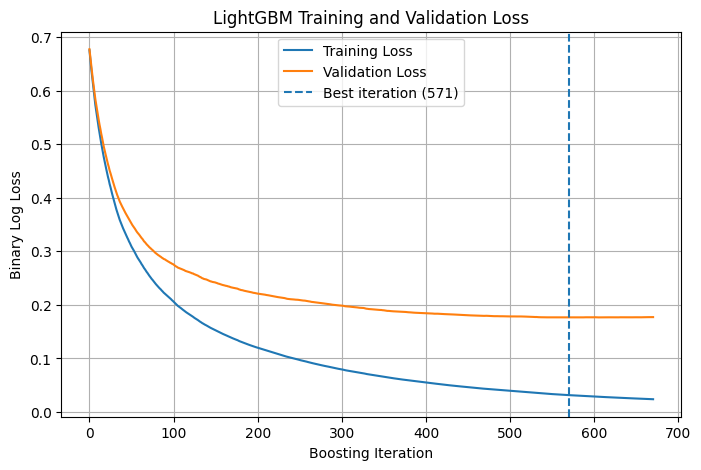

In [ ]:
# Loss Curves
import matplotlib.pyplot as plt

train_loss = evals_result["train"]["binary_logloss"]
val_loss = evals_result["validation"]["binary_logloss"]

plt.figure(figsize=(8, 5))

plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")

plt.axvline(
    lgbm.best_iteration_ - 1,
    linestyle="--",
    label=f"Best iteration ({lgbm.best_iteration_})"
)

plt.xlabel("Boosting Iteration")
plt.ylabel("Binary Log Loss")
plt.title("LightGBM Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

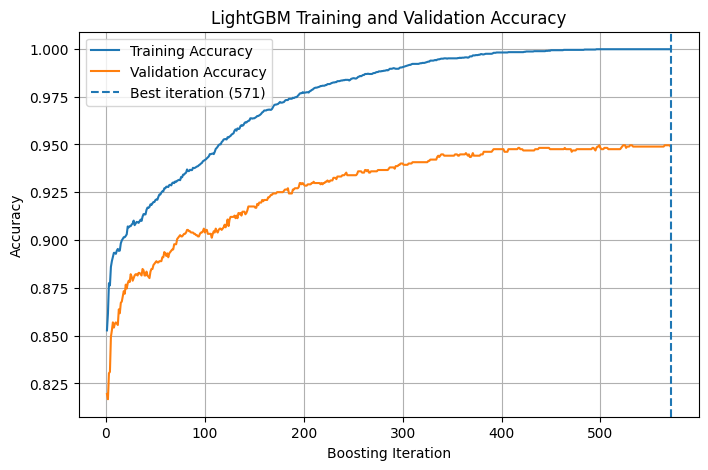

In [ ]:
# Accuracy curves
from sklearn.metrics import accuracy_score

train_accuracy = []
val_accuracy = []

for iteration in range(1, lgbm.best_iteration_ + 1):

    train_prob = lgbm.predict_proba(
        X_tr,
        num_iteration=iteration
    )[:, 1]

    val_prob = lgbm.predict_proba(
        X_val,
        num_iteration=iteration
    )[:, 1]

    train_pred = (train_prob >= 0.5).astype(int)
    val_pred = (val_prob >= 0.5).astype(int)

    train_accuracy.append(
        accuracy_score(y_tr, train_pred)
    )

    val_accuracy.append(
        accuracy_score(y_val, val_pred)
    )


plt.figure(figsize=(8, 5))

plt.plot(
    range(1, lgbm.best_iteration_ + 1),
    train_accuracy,
    label="Training Accuracy"
)

plt.plot(
    range(1, lgbm.best_iteration_ + 1),
    val_accuracy,
    label="Validation Accuracy"
)

plt.axvline(
    lgbm.best_iteration_,
    linestyle="--",
    label=f"Best iteration ({lgbm.best_iteration_})"
)

plt.xlabel("Boosting Iteration")
plt.ylabel("Accuracy")
plt.title("LightGBM Training and Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


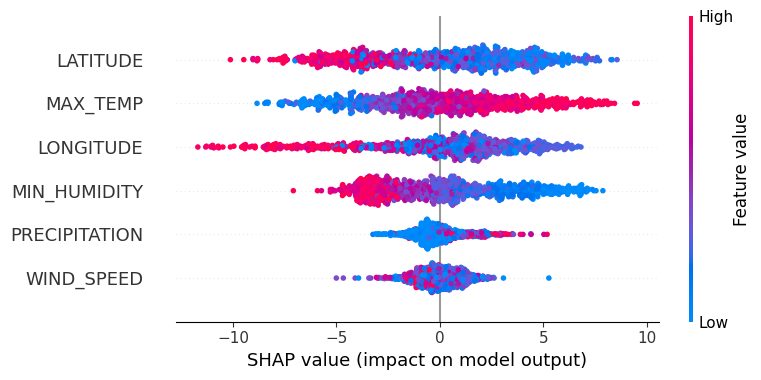

In [ ]:
# SHAP explainer
X_shap = X_test.sample(
    min(1000, len(X_test)),
    random_state=42
)

shap_values_global = explainer.shap_values(X_shap)

if isinstance(shap_values_global, list):
    shap_values_global = shap_values_global[1]

shap.summary_plot(
    shap_values_global,
    X_shap
)

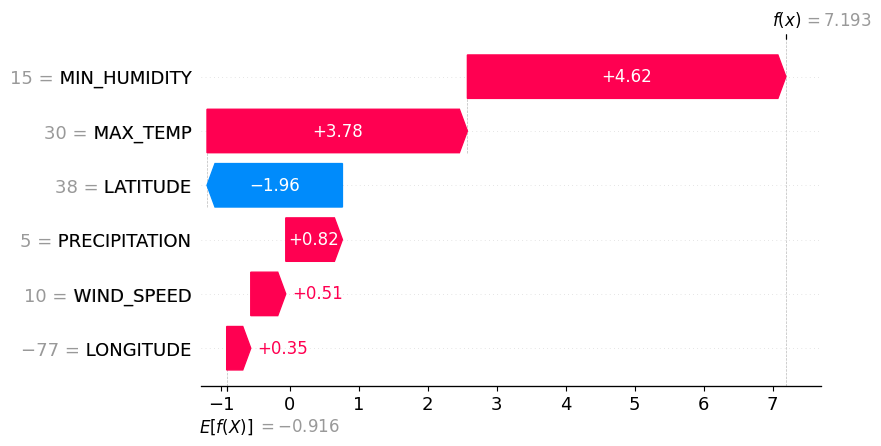

In [ ]:
# SHAP Plot
shap.plots.waterfall(
    shap.Explanation(
        values=shap_for_prediction,
        base_values=explainer.expected_value[1]
            if isinstance(explainer.expected_value, (list, np.ndarray))
            else explainer.expected_value,
        data=user_input.iloc[0].values,
        feature_names=user_input.columns
    )
)

In [ ]:
# Using optuna to find LightGBM hyperparameters
import optuna
import lightgbm as lgb

from lightgbm import LGBMClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss
)

# 1. Split training data into TRAIN and VALIDATION

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)


# 2. Optuna  function

def objective(trial):

    params = {
        "objective": "binary",
        "metric": "binary_logloss",

        # Hyperparameters to tune
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.10, log=True
        ),

        "num_leaves": trial.suggest_int(
            "num_leaves", 15, 127
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 3, 12
        ),

        "min_child_samples": trial.suggest_int(
            "min_child_samples", 10, 100
        ),

        "subsample": trial.suggest_float(
            "subsample", 0.7, 1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.7, 1.0
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha", 0.0, 5.0
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda", 0.0, 5.0
        ),

        # Large upper limit, but early stopping decides
        # how many trees are actually needed
        "n_estimators": 5000,

        "random_state": 42,
        "n_jobs": -1,
        "verbosity": -1
    }

    model = LGBMClassifier(**params)

    model.fit(
        X_tr,
        y_tr,
        eval_set=[(X_val, y_val)],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=100,
                verbose=False
            )
        ]
    )

    # Validation probabilities
    val_prob = model.predict_proba(X_val)[:, 1]

    # Use Brier score as Optuna objective
    ROC = roc_auc_score(y_val, val_prob)

    return ROC


# 3. Run Optuna

study = optuna.create_study(
    direction="minimize",
    study_name="lightgbm_wildfire"
)

study.optimize(
    objective,
    n_trials=50,
    show_progress_bar=True
)


# 4. Display best parameters

print("\nBest Brier Score:")
print(study.best_value)

print("\nBest Hyperparameters:")
for key, value in study.best_params.items():
    print(f"{key}: {value}")


# 5. Train final model using best parameters

best_params = study.best_params.copy()

best_params.update({
    "objective": "binary",
    "n_estimators": 5000,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1
})

lgbm = LGBMClassifier(**best_params)


# 6. Early stopping using VALIDATION set

lgbm.fit(
    X_tr,
    y_tr,
    eval_set=[(X_val, y_val)],
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=100,
            verbose=True
        )
    ]
)


# 7. Final evaluation on untouched TEST set


lgb_pred = lgbm.predict(X_test)
lgb_prob = lgbm.predict_proba(X_test)[:, 1]


print("FINAL TEST RESULTS")


print("Best iteration:", lgbm.best_iteration_)

print("Accuracy :", accuracy_score(y_test, lgb_pred))
print("Precision:", precision_score(y_test, lgb_pred))
print("Recall   :", recall_score(y_test, lgb_pred))
print("F1       :", f1_score(y_test, lgb_pred))
print("ROC-AUC  :", roc_auc_score(y_test, lgb_prob))

brier = brier_score_loss(y_test, lgb_prob)

print("Brier Loss:", brier)

[I 2026-10-05 11:08:01,527] A new study created in memory with name: lightgbm_wildfire


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-10-05 11:08:06,833] Trial 0 finished with value: 0.06959425616231489 and parameters: {'learning_rate': 0.08442438396089272, 'num_leaves': 82, 'max_depth': 12, 'min_child_samples': 84, 'subsample': 0.9068293064219246, 'colsample_bytree': 0.825108716293055, 'reg_alpha': 3.5122465764169037, 'reg_lambda': 2.663246993255668}. Best is trial 0 with value: 0.06959425616231489.
[I 2026-10-05 11:08:28,137] Trial 1 finished with value: 0.08028787940910483 and parameters: {'learning_rate': 0.010940384641724194, 'num_leaves': 60, 'max_depth': 3, 'min_child_samples': 82, 'subsample': 0.9171316510956639, 'colsample_bytree': 0.7884032987036713, 'reg_alpha': 0.9589302353258167, 'reg_lambda': 2.3301327960060543}. Best is trial 0 with value: 0.06959425616231489.
[I 2026-10-05 11:08:34,333] Trial 2 finished with value: 0.07279729814097606 and parameters: {'learning_rate': 0.013607979161243913, 'num_leaves': 60, 'max_depth': 12, 'min_child_samples': 80, 'subsample': 0.9983306996256951, 'colsample_b

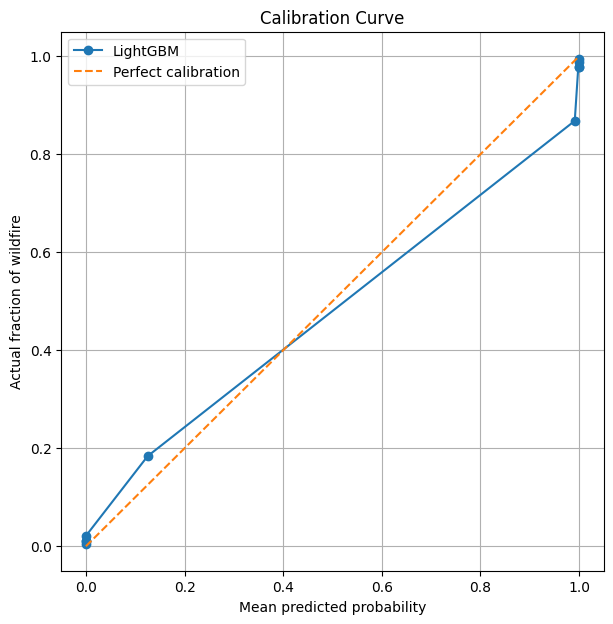

In [ ]:
# Calibration curve for probabilities
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true, prob_pred = calibration_curve(
    y_test,
    lgb_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 7))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="LightGBM"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Actual fraction of wildfire")
plt.title("Calibration Curve")
plt.legend()
plt.grid(True)

plt.show()